In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

column_names = ['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT', 'MEDV']


In [12]:
df = pd.read_csv("housing (1).csv", header=None, delimiter=r"\s+", names=column_names)


In [13]:
df.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33,36.2


In [14]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     506 non-null    float64
 1   ZN       506 non-null    float64
 2   INDUS    506 non-null    float64
 3   CHAS     506 non-null    int64  
 4   NOX      506 non-null    float64
 5   RM       506 non-null    float64
 6   AGE      506 non-null    float64
 7   DIS      506 non-null    float64
 8   RAD      506 non-null    int64  
 9   TAX      506 non-null    float64
 10  PTRATIO  506 non-null    float64
 11  B        506 non-null    float64
 12  LSTAT    506 non-null    float64
 13  MEDV     506 non-null    float64
dtypes: float64(12), int64(2)
memory usage: 55.5 KB


In [15]:
df.describe()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
count,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000
mean,3.613524,11.363636,11.136779,0.069170,0.554695,6.284634,68.574901,3.795043,9.549407,408.237154,18.455534,356.674032,12.653063,22.532806
std,8.601545,23.322453,6.860353,0.253994,0.115878,0.702617,28.148861,2.105710,8.707259,168.537116,2.164946,91.294864,7.141062,9.197104
min,0.006320,0.000000,0.460000,0.000000,0.385000,3.561000,2.900000,1.129600,1.000000,187.000000,12.600000,0.320000,1.730000,5.000000
25%,0.082045,0.000000,5.190000,0.000000,0.449000,5.885500,45.025000,2.100175,4.000000,279.000000,17.400000,375.377500,6.950000,17.025000
50%,0.256510,0.000000,9.690000,0.000000,0.538000,6.208500,77.500000,3.207450,5.000000,330.000000,19.050000,391.440000,11.360000,21.200000
75%,3.677083,12.500000,18.100000,0.000000,0.624000,6.623500,94.075000,5.188425,24.000000,666.000000,20.200000,396.225000,16.955000,25.000000
max,88.976200,100.000000,27.740000,1.000000,0.871000,8.780000,100.000000,12.126500,24.000000,711.000000,22.000000,396.900000,37.970000,50.000000


<Axes: xlabel='MEDV', ylabel='Count'>

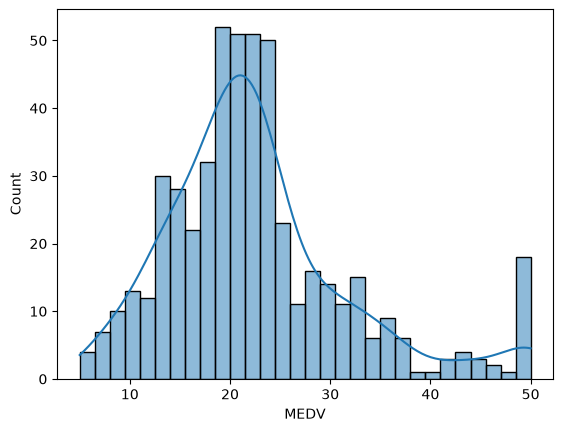

In [20]:
sns.histplot(df['MEDV'], bins=30, kde=True)

In [22]:
from scipy.stats import skew
df.apply(skew).sort_values(ascending=False)

CRIM       5.207652
CHAS       3.395799
ZN         2.219063
MEDV       1.104811
DIS        1.008779
RAD        1.001833
LSTAT      0.903771
NOX        0.727144
TAX        0.667968
RM         0.402415
INDUS      0.294146
AGE       -0.597186
PTRATIO   -0.799945
B         -2.881798
dtype: float64

In [24]:
X=df.drop('MEDV', axis=1)
y=df['MEDV']

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

from sklearn.preprocessing import PowerTransformer
pt_X = PowerTransformer(method='yeo-johnson', standardize=True)

X_train_transformed = pt_X.fit_transform(X_train)
X_test_transformed = pt_X.transform(X_test)



In [25]:
X_train_transformed_df = pd.DataFrame(X_train_transformed, columns=X_train.columns)

array([[ 1.63241784, -0.61143074,  1.02590994, ...,  0.87993863,
        -0.66036566,  1.51915973],
       [ 0.00589163, -0.61143074, -0.22019835, ...,  1.42975161,
         0.5948799 , -0.42209432],
       [-0.98991095,  1.64526707, -0.5893983 , ..., -0.79900944,
        -0.35482167, -0.54827284],
       ...,
       [-1.04236674,  1.69862748, -1.60592802, ..., -0.76022264,
         0.44762642, -0.96180689],
       [ 1.57057069, -0.61143074,  1.02590994, ...,  0.87993863,
        -2.75987851,  1.38556565],
       [-0.56025693, -0.61143074, -0.15266118, ...,  1.3575532 ,
        -2.7827244 , -0.04522593]], shape=(404, 13))

In [26]:
from scipy.stats import boxcox
y_train_transformed, lambda_y = boxcox(y_train + 1)  # Adding 1 to avoid zero values
def inverse_boxcox(y, lambda_):
    if lambda_ == 0:
        return np.exp(y) - 1
    else:
        return np.power(y * lambda_ + 1, 1 / lambda_) - 1

In [28]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train_transformed, y_train_transformed)


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](13,)","[-0.04,-0. ,-0. ,...,-0.11, 0.06,-0.41]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,4.113
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,13
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(13)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](13,)","[52. ,23.46,21.43,..., 8.08, 7.22, 6.13]"


In [29]:
y_pred_transformed = model.predict(X_test_transformed)
y_pred = inverse_boxcox(y_pred_transformed, lambda_y)
y_pred_original = inverse_boxcox(y_train_transformed, lambda_y)
y_pred_transformed

array([4.56149978, 5.2201817 , 3.57857366, 4.50521744, 3.57835419,
       4.05830789, 3.681643  , 3.42947606, 3.84858641, 3.92043573,
       4.14155464, 3.77028423, 2.60973171, 3.97481152, 3.94599095,
       3.96010743, 3.97451924, 3.00193817, 5.33819667, 3.55886357,
       4.53172866, 4.59539624, 3.23563565, 4.11131801, 3.59060672,
       3.42988535, 4.16467487, 3.38340431, 4.00398697, 3.84016749,
       4.10050174, 4.3929168 , 4.11636079, 3.8308575 , 3.36274192,
       3.76060607, 4.92654293, 4.1059635 , 4.06782791, 4.30484494,
       3.47861009, 4.76563804, 5.44019114, 3.80436998, 4.42523895,
       3.5855519 , 3.42783551, 4.42278714, 3.62697683, 4.68062074,
       3.99378332, 5.05529035, 3.51979436, 4.34615768, 5.30923633,
       3.83543396, 3.66098157, 5.01039191, 4.30731332, 3.5325994 ,
       4.17510522, 4.8525588 , 4.93901323, 3.60606227, 4.34314444,
       3.67805454, 3.72950802, 4.45933133, 4.80335535, 3.25720143,
       3.95652032, 4.22319035, 3.16987977, 4.04316063, 4.14046

In [33]:
from sklearn.metrics import mean_squared_error, r2_score
y_pred_transformed = model.predict(X_test_transformed)
y_pred_original = inverse_boxcox(y_pred_transformed, lambda_y)
y_pred_transformed
print("R-squared Score:", r2_score(y_test, y_pred_original))

R-squared Score: 0.7501900555510109
